# Customer Churn Prediction
**Data Analytics Internship · Project 01**

Which telecom customers are most likely to leave? This notebook explores churn patterns, compares classifiers on a held-out set, and translates the results into a retention use case.

**Source** [IBM Telco Customer Churn sample](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv).

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv(Path("data") / "telco.csv")
assert df["customerID"].is_unique and set(df["Churn"]) == {"Yes", "No"}
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print(f"Customers: {len(df):,} | Churned: {df['Churn'].sum():,} ({df['Churn'].mean():.1%})")
print(f"Missing TotalCharges: {df['TotalCharges'].isna().sum()}")

Customers: 7,043 | Churned: 1,869 (26.5%)
Missing TotalCharges: 11


## 1. Explore training data

Reserve 20% as a stratified test set before looking at patterns. Customer IDs identify rows and are excluded from the model. Churn rates below describe associations in the sample.

                customers  rate
Contract                       
Month-to-month       3102 42.7%
One year             1173 11.1%
Two year             1359  2.9%

        customers  rate
tenure                 
0–6          1170 52.2%
7–12          567 37.2%
13–24         818 28.6%
25–48        1290 20.2%
49–72        1789  9.9%



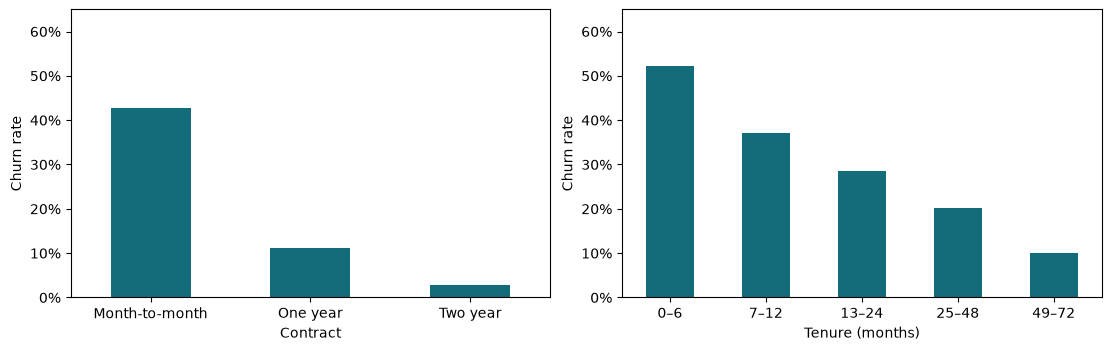

In [6]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
eda = X_train.assign(Churn=y_train)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
tenure = pd.cut(eda["tenure"], [-1, 6, 12, 24, 48, 72],
                labels=["0–6", "7–12", "13–24", "25–48", "49–72"])
for group, ax, label in [(eda["Contract"], axes[0], "Contract"),
                         (tenure, axes[1], "Tenure (months)")]:
    summary = eda.groupby(group, observed=True)["Churn"].agg(customers="size", rate="mean")
    print(summary.to_string(float_format=lambda value: f"{value:.1%}"), end="\n\n")
    summary["rate"].plot.bar(ax=ax, color="#126c79", rot=0, ylim=(0, 0.65))
    ax.set(xlabel=label, ylabel="Churn rate")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

## 2. Fit and compare models

Impute missing values, scale numeric features, and encode categories inside each pipeline so preprocessing learns only from training data. Compare Logistic Regression and Random Forest against a majority-class baseline.

Training customers: 5,634 | Test customers: 1,409
                     Accuracy  Recall  Precision  ROC-AUC
Model                                                    
Majority baseline       0.735   0.000      0.000    0.500
Logistic Regression     0.806   0.559      0.657    0.842
Random Forest           0.796   0.497      0.650    0.837


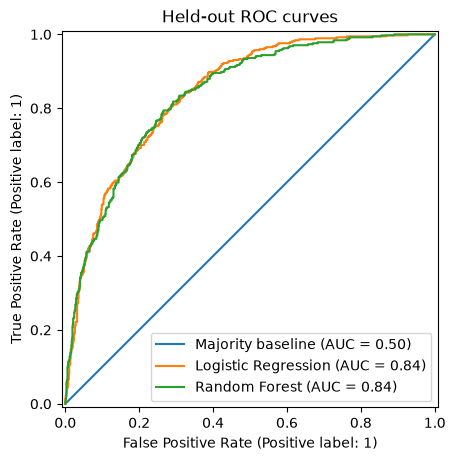

In [7]:
numeric = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
categorical = make_pipeline(SimpleImputer(strategy="most_frequent"),
                            OneHotEncoder(handle_unknown="ignore"))
preprocessing = ColumnTransformer([
    ("numeric", numeric, make_column_selector(dtype_include="number")),
    ("categorical", categorical, make_column_selector(dtype_exclude="number")),
])
estimators = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                             random_state=42, n_jobs=2),
}
scores, predictions = [], {}
fig, ax = plt.subplots(figsize=(6.6, 4.5), constrained_layout=True)
for name, estimator in estimators.items():
    model = make_pipeline(preprocessing, estimator)
    model.fit(X_train, y_train)
    probability = model.predict_proba(X_test)[:, 1]
    predicted = model.predict(X_test)
    predictions[name] = predicted
    scores.append({"Model": name, "Accuracy": accuracy_score(y_test, predicted),
                   "Recall": recall_score(y_test, predicted),
                   "Precision": precision_score(y_test, predicted, zero_division=0),
                   "ROC-AUC": roc_auc_score(y_test, probability)})
    RocCurveDisplay.from_predictions(y_test, probability, name=name, ax=ax)
ax.set_title("Held-out ROC curves")
results = pd.DataFrame(scores).set_index("Model")
print(f"Training customers: {len(X_train):,} | Test customers: {len(X_test):,}")
print(results.round(3).to_string())
plt.show()

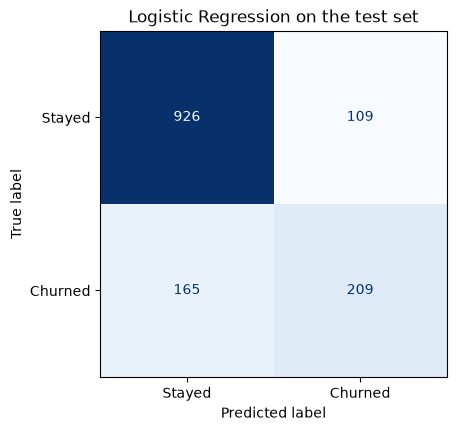

In [8]:
fig, ax = plt.subplots(figsize=(5.1, 4.2), constrained_layout=True)
ConfusionMatrixDisplay.from_predictions(y_test, predictions["Logistic Regression"],
                                        display_labels=["Stayed", "Churned"],
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Logistic Regression on the test set")
plt.show()

## 3. Retention use case

Compare recall with accuracy. The majority baseline can look respectable on accuracy even though it flags none of the customers who actually churned. Month-to-month contracts and the earliest tenure band show higher observed churn rates in training data. A retention team could use the model scores to prioritize outreach and then run a controlled pilot to measure whether it reduces churn.

These scores come from one random split of a sample dataset. Before using the model operationally, validate on newer customers and select an outreach threshold using validation data and the costs of missed churn versus unnecessary outreach.